# Customer Churn Prediction

In [2]:
!pip install pandas numpy matplotlib seaborn

     ---------------------------------------- 9.9/9.9 MB 2.3 MB/s eta 0:00:00
  Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl (12.6 MB)
     ---------------------------------------- 9.3/9.3 MB 2.1 MB/s eta 0:00:00
  Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
     -------------------------------------- 347.5/347.5 kB 1.8 MB/s eta 0:00:00
  Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl (225 kB)
  Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
     ---------------------------------------- 2.5/2.5 MB 2.8 MB/s eta 0:00:00
     -------------------------------------- 70.7/70.7 kB 387.8 kB/s eta 0:00:00
     ---------------------------------------- 7.2/7.2 MB 2.6 MB/s eta 0:00:00
     -------------------------------------- 126.4/126.4 kB 1.8 MB/s eta 0:00:00



[notice] A new release of pip available: 22.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### 1. Dataset Investigation

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../data/raw/Telco-Customer-Churn.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [7]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [10]:
df['Churn'].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

Investigate "TotalCharges" Column 

MonthlyCharges - float64
TotalCharges - str


In [ ]:
df['TotalCharges'].value_counts().tail(20)  

TotalCharges
6479.4     1
3626.35    1
1679.4     1
403.35     1
931.55     1
4326.25    1
263.05     1
39.25      1
3316.1     1
75.75      1
2625.25    1
6886.25    1
1495.1     1
743.3      1
1419.4     1
1990.5     1
7362.9     1
346.45     1
306.6      1
6844.5     1
Name: count, dtype: int64

value_count() - counts the frequency of each distinct value in the column and sorts the result from most frequent to least frequent.
tail(20) - return only the last 20 rows

In [ ]:
df[df['TotalCharges'].str.strip() == ""]  # finds all rows where TotalCharges contains empty spaces or completely blank.

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


There are 11 records where TotalCharges is an empty string
important:
tenure = 0
TotalCharges = ""
Churn = No

In [13]:
# counts how many rows in the TotalCharges column contain only empty
# spaces or are completely blank.
df["TotalCharges"].str.strip().eq("").sum()

np.int64(11)

In [14]:
df[df["tenure"] == 0][["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


In [15]:
df["tenure"].value_counts().sort_index().head(10)

tenure
0     11
1    613
2    238
3    200
4    176
5    133
6    110
7    131
8    123
9    119
Name: count, dtype: int64

In [16]:
df[df["tenure"] == 0]["Churn"].value_counts()

Churn
No    11
Name: count, dtype: int64

- All 11 customers with tenure = 0 have an empty TotalCharges, and all 11 have Churn = No.
- This strongly suggests the blank TotalCharges values represent new customers who have not accumulated any total charges yet, rather than corrupted customer records.

In [17]:
categorical_cols = df.select_dtypes(include='str').columns

for col in categorical_cols:
    print(f"\n---{col}---")
    print(df[col].value_counts())


---customerID---
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

---gender---
gender
Male      3555
Female    3488
Name: count, dtype: int64

---Partner---
Partner
No     3641
Yes    3402
Name: count, dtype: int64

---Dependents---
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

---PhoneService---
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

---MultipleLines---
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

---InternetService---
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

---OnlineSecurity---
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

---OnlineBackup---
OnlineBackup
No

In [18]:
numeric_cols = ["SeniorCitizen", "tenure", "MonthlyCharges"]

df[numeric_cols].describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [19]:
df.groupby("Churn")[numeric_cols].mean()

,SeniorCitizen,tenure,MonthlyCharges
Churn,,,
No,0.128721,37.569965,61.265124
Yes,0.254682,17.979133,74.441332


In [20]:
df.groupby("Contract")["Churn"].value_counts(normalize=True).unstack() * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


### 2. Data Cleaning

In [4]:
df_clean = df.copy()

In [5]:
# Convert TotalCharges to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"], 
    errors='coerce'
)

In [5]:
df_clean["TotalCharges"].isnull().sum()

np.int64(11)

In [24]:
df_clean[df_clean["TotalCharges"].isnull()][
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [6]:
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

In [7]:
df_clean["TotalCharges"].isnull().sum()

np.int64(0)

In [8]:
df_clean["TotalCharges"].dtype

dtype('float64')

In [28]:
print("Original shape: ", df.shape)
print("Cleaned shape: ", df_clean.shape)

Original shape:  (7043, 21)
Cleaned shape:  (7043, 21)


In [29]:
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate customer IDs:", df_clean["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


In [7]:
X = df_clean.drop(columns=["customerID", "Churn"])
y = df_clean["Churn"]

In [10]:
print("X shape: ", X.shape)
print("y shape: ", y.shape)

X shape:  (7043, 19)
y shape:  (7043,)


In [9]:
X.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


In [10]:
y.head()

0     No
1     No
2    Yes
3     No
4    Yes
Name: Churn, dtype: str

In [8]:
# Encode the target variable
y = y.map({"Yes": 1, "No": 0})

In [12]:
y.value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

### 3. Data split

In [13]:
!pip install scikit-learn

     ---------------------------------------- 8.3/8.3 MB 617.7 kB/s eta 0:00:00
  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl (36.6 MB)
     ------------------------------------ 306.1/306.1 kB 420.9 kB/s eta 0:00:00
     ------------------------------------ 474.0/474.0 kB 761.6 kB/s eta 0:00:00
  Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)



[notice] A new release of pip available: 22.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


80% training + 20% temporary data

In [9]:
# Create the first split
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, 
    y,
    test_size=0.20,
    stratify=y,  # Ensures that the proportion of classes in y is maintained in the splits 
    random_state=42
)

10% validation + 10% test

In [10]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, 
    y_temp,
    test_size=0.50,  # Split the remaining 20% into 10% validation and 10% test
    stratify=y_temp,  # Ensures that the proportion of classes in y is maintained in the splits 
    random_state=42
)

In [15]:
print("Training: ", X_train.shape, y_train.shape)
print("Validation: ", X_val.shape, y_val.shape)
print("Test: ", X_test.shape, y_test.shape)

Training:  (5634, 19) (5634,)
Validation:  (704, 19) (704,)
Test:  (705, 19) (705,)


In [17]:
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True) * 100)

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True) * 100)


Training target distribution:
Churn
0    73.464679
1    26.535321
Name: proportion, dtype: float64

Validation target distribution:
Churn
0    73.4375
1    26.5625
Name: proportion, dtype: float64

Test target distribution:
Churn
0    73.475177
1    26.524823
Name: proportion, dtype: float64


In [18]:
print(X_train.dtypes)

print("\nData type counts:")
print(X_train.dtypes.value_counts())

gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
dtype: object

Data type counts:
str        15
int64       2
float64     2
Name: count, dtype: int64


In [19]:
print("\nMissing values:")
print(X_train.isnull().sum())


Missing values:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
dtype: int64


### 4. Build the preprocessing pipeline

In [11]:
numerical_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

In [21]:
print("Numeric features: ", len(numerical_features))
print("Categorical features: ", len(categorical_features))
print("Total features: ", len(numerical_features) + len(categorical_features))

Numeric features:  4
Categorical features:  15
Total features:  19


In [12]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [13]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

Why handle_unknown="ignore"?

sometimes test set may contains a category that wasn't present during training.

Instead of crashing, the encoder can safely handle it.

In [24]:
print(preprocessor)

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['SeniorCitizen', 'tenure', 'MonthlyCharges',
                                  'TotalCharges']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['gender', 'Partner', 'Dependents',
                                  'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'TechSupport', 'StreamingTV',
                                  'StreamingMovies', 'Contract',
                                  'PaperlessBilling', 'PaymentMethod'])])


### 5. model traning

Model 1: Logistic Regression

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

In [20]:
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]
)

In [21]:
logistic_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

Baseline evaluation

In [28]:
# Make validation predictions
y_val_pred = logistic_pipeline.predict(X_val)
y_val_prob = logistic_pipeline.predict_proba(X_val)[:, 1]  # Get the probability of the positive class

In [29]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,   
    roc_auc_score
)

print("Validation Accuracy: ", accuracy_score(y_val, y_val_pred))
print("Validation Precision: ", precision_score(y_val, y_val_pred))
print("Validation Recall: ", recall_score(y_val, y_val_pred))
print("Validation F1-Score: ", f1_score(y_val, y_val_pred))
print("Validation AUC-ROC: ", roc_auc_score(y_val, y_val_prob))

Validation Accuracy:  0.8125
Validation Precision:  0.6687116564417178
Validation Recall:  0.5828877005347594
Validation F1-Score:  0.6228571428571429
Validation AUC-ROC:  0.8494192120315684


In [30]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, y_val_pred)

print("Confusion Matrix:\n", cm)

Confusion Matrix:
 [[463  54]
 [ 78 109]]


In [31]:
baseline_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_val, y_val_pred),
    "Precision": precision_score(y_val, y_val_pred),
    "Recall": recall_score(y_val, y_val_pred),
    "F1-Score": f1_score(y_val, y_val_pred),
    "AUC-ROC": roc_auc_score(y_val, y_val_prob)
}

baseline_results

{'Model': 'Logistic Regression',
 'Accuracy': 0.8125,
 'Precision': 0.6687116564417178,
 'Recall': 0.5828877005347594,
 'F1-Score': 0.6228571428571429,
 'AUC-ROC': 0.8494192120315684}

Model 2 - Random Forest Classifier

In [32]:
from sklearn.ensemble import RandomForestClassifier

In [33]:
# Create the pipeline
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model", 
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                class_weight="balanced"
            )
        )
    ]
)

In [34]:
rf_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

Model 3 - Gradient Boosting

In [35]:
from sklearn.ensemble import GradientBoostingClassifier

In [36]:
gb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model", 
            GradientBoostingClassifier(
                n_estimators=100,
                learning_rate=0.1,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

In [37]:
gb_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [38]:
# Evaluate both models
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,   
    roc_auc_score
)

def evaluate_model(model, X_val, y_val):
    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]  

    return {
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1-Score": f1_score(y_val, y_pred),
        "AUC-ROC": roc_auc_score(y_val, y_prob)
    }

In [39]:
logistic_results = evaluate_model(logistic_pipeline, X_val, y_val)

rf_results = evaluate_model(rf_pipeline, X_val, y_val)

gb_results = evaluate_model(gb_pipeline, X_val, y_val)

In [41]:
results = pd.DataFrame(
    [logistic_results, rf_results, gb_results],
    index=["Logistic Regression", "Random Forest", "Gradient Boosting"]
)

results

,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Logistic Regression,0.812500,0.668712,0.582888,0.622857,0.849419
Random Forest,0.778409,0.570776,0.668449,0.615764,0.831453
Gradient Boosting,0.813920,0.681818,0.561497,0.615836,0.847723


In [42]:
# Get probability predictions
logistic_prob = logistic_pipeline.predict_proba(X_val)[:, 1]
rf_prob = rf_pipeline.predict_proba(X_val)[:, 1]
gb_prob = gb_pipeline.predict_proba(X_val)[:, 1]

In [43]:
# Test with several thresholds
from sklearn.metrics import precision_score, recall_score, f1_score

def threshold_results(y_true, y_prob, thresholds):
    results = []

    for threshold in thresholds:
        y_pred = (y_prob >= threshold).astype(int)

        results.append({
            "Threshold": threshold,
            "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred),
            "F1-Score": f1_score(y_true, y_pred)
        })
    return pd.DataFrame(results)

In [44]:
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

logistic_threshold_results = threshold_results(
    y_val, 
    logistic_prob, 
    thresholds
)

logistic_threshold_results

,Threshold,Precision,Recall,F1-Score
0,0.3,0.500000,0.748663,0.599572
1,0.4,0.560345,0.695187,0.620525
2,0.5,0.668712,0.582888,0.622857
3,0.6,0.740741,0.427807,0.542373
4,0.7,0.808511,0.203209,0.324786


In [45]:
rf_threshold_results = threshold_results(
    y_val, 
    rf_prob, 
    thresholds
)

rf_threshold_results

,Threshold,Precision,Recall,F1-Score
0,0.3,0.458213,0.850267,0.595506
1,0.4,0.503571,0.754011,0.603854
2,0.5,0.565611,0.668449,0.612745
3,0.6,0.587209,0.540107,0.562674
4,0.7,0.630769,0.438503,0.517350


In [47]:
gb_threshold_results = threshold_results(
    y_val, 
    gb_prob, 
    thresholds
)

gb_threshold_results

,Threshold,Precision,Recall,F1-Score
0,0.3,0.514493,0.759358,0.613391
1,0.4,0.591549,0.673797,0.630000
2,0.5,0.681818,0.561497,0.615836
3,0.6,0.757576,0.401070,0.524476
4,0.7,0.857143,0.288770,0.432000


In [48]:
fine_thresholds = np.arange(0.20, 0.81, 0.05)

logistic_fine = threshold_results(
    y_val, 
    logistic_prob, 
    fine_thresholds
)

rf_fine = threshold_results(
    y_val, 
    rf_prob, 
    fine_thresholds
)

gb_fine = threshold_results(
    y_val, 
    gb_prob, 
    fine_thresholds
)

print("Logistic Regression: ")
display(logistic_fine)

print("\nRandom Forest: ")
display(rf_fine)

print("\nGradient Boosting")
display(gb_fine)

Logistic Regression: 


,Threshold,Precision,Recall,F1-Score
0,0.20,0.462644,0.860963,0.601869
1,0.25,0.488746,0.812834,0.610442
2,0.30,0.500000,0.748663,0.599572
3,0.35,0.535714,0.721925,0.615034
4,0.40,0.560345,0.695187,0.620525
5,0.45,0.599010,0.647059,0.622108
6,0.50,0.668712,0.582888,0.622857
7,0.55,0.691729,0.491979,0.575000
8,0.60,0.740741,0.427807,0.542373
9,0.65,0.780488,0.342246,0.475836



Random Forest: 


,Threshold,Precision,Recall,F1-Score
0,0.20,0.407674,0.909091,0.562914
1,0.25,0.437824,0.903743,0.589878
2,0.30,0.458213,0.850267,0.595506
3,0.35,0.485714,0.818182,0.609562
4,0.40,0.503571,0.754011,0.603854
5,0.45,0.543307,0.737968,0.625850
6,0.50,0.565611,0.668449,0.612745
7,0.55,0.577889,0.614973,0.595855
8,0.60,0.587209,0.540107,0.562674
9,0.65,0.598726,0.502674,0.546512



Gradient Boosting


,Threshold,Precision,Recall,F1-Score
0,0.20,0.465875,0.839572,0.599237
1,0.25,0.488525,0.796791,0.605691
2,0.30,0.514493,0.759358,0.613391
3,0.35,0.553719,0.716578,0.624709
4,0.40,0.591549,0.673797,0.630000
5,0.45,0.633880,0.620321,0.627027
6,0.50,0.681818,0.561497,0.615836
7,0.55,0.704000,0.470588,0.564103
8,0.60,0.757576,0.401070,0.524476
9,0.65,0.784810,0.331551,0.466165


### 6. Hyperparameter tuning

In [49]:
from sklearn.model_selection import GridSearchCV

In [50]:
# Tune logistic regression - create a parameter grid
logistic_param_grid = {
    "model__C": [0.01, 0.1, 1, 10],   # C - controls the strength of regularization.
    "model__class_weight": [None, "balanced"]  # tells the model to give more importance to the minority churn class.
}

In [51]:
logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_param_grid,
    scoring="recall",
    cv=5,
    n_jobs=-1
)

logistic_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...], 'model__class_weight': [None, 'balanced']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosit

In [52]:
print("Best Logistic Regression parameters:")
print(logistic_grid.best_params_)

print("\nBest cross-validation recall:")
print(logistic_grid.best_score_)

Best Logistic Regression parameters:
{'model__C': 1, 'model__class_weight': 'balanced'}

Best cross-validation recall:
0.8040133779264215


In [53]:
rf_param_grid = {
    "model__n_estimators": [200, 300],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__class_weight": ["balanced"]
}

In [54]:
rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring="recall",
    cv=5,
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__class_weight': ['balanced'], 'model__max_depth': [None, 10, ...], 'model__min_samples_split': [2, 5], 'model__n_estimators': [200, 300]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for call

In [55]:
print("Best Random Forest parameters:")
print(rf_grid.best_params_)

print("\nBest cross-validation recall:")
print(rf_grid.best_score_)

Best Random Forest parameters:
{'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 300}

Best cross-validation recall:
0.7565217391304347


In [56]:
gb_param_grid = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3]
}

In [57]:
gb_grid = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=gb_param_grid,
    scoring="recall",
    cv=5,
    n_jobs=-1
)

gb_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__learning_rate': [0.05, 0.1], 'model__max_depth': [2, 3], 'model__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, def

In [58]:
print("Best Gradient Boosting parameters:")
print(gb_grid.best_params_)

print("\nBest cross-validation recall:")
print(gb_grid.best_score_)

Best Gradient Boosting parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 100}

Best cross-validation recall:
0.528428093645485


In [59]:
tuned_models = {
    "Logistic Regression": logistic_grid.best_estimator_,
    "Random Forest": rf_grid.best_estimator_,
    "Gradient Boosting": gb_grid.best_estimator_
}

In [61]:
tuned_results = []

for model_name, model in tuned_models.items():

    y_pred = model.predict(X_val)
    y_prob =model.predict_proba(X_val)[:, 1]

    tuned_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1-Score": f1_score(y_val, y_pred),
        "AUC-ROC": roc_auc_score(y_val, y_prob)
    })

tuned_results_df = pd.DataFrame(tuned_results)

tuned_results_df

,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,Logistic Regression,0.728693,0.493289,0.786096,0.606186,0.849099
1,Random Forest,0.744318,0.512545,0.764706,0.613734,0.845323
2,Gradient Boosting,0.813920,0.681818,0.561497,0.615836,0.847723


### 7. Threshold analysis on the tuned models

In [62]:
tuned_logistic_prob = logistic_grid.best_estimator_.predict_proba(X_val)[:, 1]
tuned_rf_prob = rf_grid.best_estimator_.predict_proba(X_val)[:, 1]
tuned_gb_prob = gb_grid.best_estimator_.predict_proba(X_val)[:, 1]

In [63]:
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

In [64]:
tuned_logistic_thresholds = threshold_results(
    y_val,
    tuned_logistic_prob,
    thresholds
)

tuned_rf_thresholds = threshold_results(
    y_val,
    tuned_rf_prob,
    thresholds
)

tuned_gb_thresholds = threshold_results(
    y_val,
    tuned_gb_prob,
    thresholds
)

In [65]:
print("Logistic Regression")
display(tuned_logistic_thresholds)

print("Random Forest")
display(tuned_rf_thresholds)

print("Gradient Boosting")
display(tuned_gb_thresholds)

Logistic Regression


,Threshold,Precision,Recall,F1-Score
0,0.20,0.390558,0.973262,0.557427
1,0.25,0.403670,0.941176,0.565008
2,0.30,0.425061,0.925134,0.582492
3,0.35,0.439474,0.893048,0.589065
4,0.40,0.461538,0.866310,0.602230
5,0.45,0.470238,0.844920,0.604207
6,0.50,0.493289,0.786096,0.606186
7,0.55,0.503597,0.748663,0.602151
8,0.60,0.531496,0.721925,0.612245


Random Forest


,Threshold,Precision,Recall,F1-Score
0,0.20,0.393407,0.957219,0.557632
1,0.25,0.407494,0.930481,0.566775
2,0.30,0.431122,0.903743,0.583765
3,0.35,0.448179,0.855615,0.588235
4,0.40,0.467890,0.818182,0.595331
5,0.45,0.486842,0.791444,0.602851
6,0.50,0.512545,0.764706,0.613734
7,0.55,0.547619,0.737968,0.628702
8,0.60,0.565217,0.695187,0.623501


Gradient Boosting


,Threshold,Precision,Recall,F1-Score
0,0.20,0.465875,0.839572,0.599237
1,0.25,0.488525,0.796791,0.605691
2,0.30,0.514493,0.759358,0.613391
3,0.35,0.553719,0.716578,0.624709
4,0.40,0.591549,0.673797,0.630000
5,0.45,0.633880,0.620321,0.627027
6,0.50,0.681818,0.561497,0.615836
7,0.55,0.704000,0.470588,0.564103
8,0.60,0.757576,0.401070,0.524476


In [66]:
from sklearn.metrics import confusion_matrix

selected_thresholds = {
    "Logistic Regression (0.40)": (
        tuned_logistic_prob,
        0.40
    ),
    "Logistic Regression (0.50)": (
            tuned_logistic_prob,
            0.50
    ),
    "Random Forest (0.40)": (
        tuned_rf_prob,
        0.40
    ),
    "Random Forest (0.50)": (
        tuned_rf_prob,
        0.50
    ),
    "Gradient Boosting (0.40)": (
        tuned_gb_prob,
        0.40
    ),
}

for name, (probabilities, threshold) in selected_thresholds.items():

    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions
    ).ravel()

    print(f"\n{name}")
    print(f"TN: {tn}")
    print(f"FP: {fp}")
    print(f"FN: {fn}")
    print(f"TP: {tp}")


Logistic Regression (0.40)
TN: 328
FP: 189
FN: 25
TP: 162

Logistic Regression (0.50)
TN: 366
FP: 151
FN: 40
TP: 147

Random Forest (0.40)
TN: 343
FP: 174
FN: 34
TP: 153

Random Forest (0.50)
TN: 381
FP: 136
FN: 44
TP: 143

Gradient Boosting (0.40)
TN: 430
FP: 87
FN: 61
TP: 126


### 8. Final Model Training

In [15]:
X_train_final = pd.concat([X_train, X_val])
y_train_final = pd.concat([y_train, y_val])

In [23]:
print("Final training feature shape: ", X_train_final.shape)
print("Final training target shape: ", y_train_final.shape)

Final training feature shape:  (6338, 19)
Final training target shape:  (6338,)


In [16]:
# Create the final Logistic Regression model
final_model = Pipeline(
    steps=[
        ("Preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                C=1,
                class_weight="balanced",
                max_iter=1000
            )
        )
    ]
)

In [17]:
final_model.fit(X_train_final, y_train_final)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [26]:
# Generate test probabilities
y_test_prob = final_model.predict_proba(X_test)[:, 1]

In [27]:
final_threshold = 0.40

y_test_pred = (y_test_prob >= final_threshold).astype(int)

In [28]:
# Calculate final test metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
test_auc = roc_auc_score(y_test, y_test_prob)

print("Final Test Results")
print("------------------")
print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1-Score : {test_f1:.4f}")
print(f"AUC-ROC  : {test_auc:.4f}")

Final Test Results
------------------
Accuracy : 0.7035
Precision: 0.4680
Recall   : 0.8610
F1-Score : 0.6064
AUC-ROC  : 0.8355


In [29]:
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred
).ravel()

print("\nConfusion Matrix")
print("----------------")
print(f"TN: {tn}")
print(f"FP: {fp}")
print(f"FN: {fn}")
print(f"TP: {tp}")


Confusion Matrix
----------------
TN: 335
FP: 183
FN: 26
TP: 161


### 9. Error Analysis

In [32]:
# Step 1 — Create the final test prediction dataset
error_analysis = X_test.copy()

error_analysis["Actual"] = y_test.values
error_analysis["Predicted"] = y_test_pred
error_analysis["Churn_Probability"] = y_test_prob

error_analysis["Error_Type"] = "Correct"

error_analysis.loc[
    (error_analysis["Actual"] == 1) &
    (error_analysis["Predicted"] == 0),
    "Error_Type"
] = "False Negative"

error_analysis.loc[
    (error_analysis["Actual"] == 0) &
    (error_analysis["Predicted"] == 1),
    "Error_Type"
] = "False Positive"

error_analysis.loc[
    (error_analysis["Actual"] == 1) &
    (error_analysis["Predicted"] == 1),
    "Error_Type"
] = "True Positive"

error_analysis.loc[
    (error_analysis["Actual"] == 0) &
    (error_analysis["Predicted"] == 0),
    "Error_Type"
] = "True Negative"

error_analysis.loc[
    (error_analysis["Actual"] == 0) &
    (error_analysis["Predicted"] == 0),
    "Error_Type"
] = "Ture Negative"

In [33]:
print(error_analysis["Error_Type"].value_counts())

Error_Type
Ture Negative     335
False Positive    183
True Positive     161
False Negative     26
Name: count, dtype: int64


In [ ]:
# Step 2 - Look specifically at the missed churners
false_negatives = error_analysis[
    error_analysis["Error_Type"] == "False Negative"
]

false_negatives

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual,Predicted,Churn_Probability,Error_Type
4513,Female,1,Yes,Yes,72,Yes,Yes,DSL,Yes,Yes,...,Yes,Two year,No,Credit card (automatic),92.45,6440.25,1,0,0.031223,False Negative
6157,Male,0,No,No,3,Yes,No,No,No internet service,No internet service,...,No internet service,Month-to-month,No,Mailed check,19.85,64.55,1,0,0.374414,False Negative
5581,Male,0,Yes,Yes,68,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Two year,Yes,Electronic check,113.15,7856.00,1,0,0.176584,False Negative
6137,Female,0,No,No,5,Yes,No,DSL,Yes,No,...,No,Month-to-month,No,Credit card (automatic),53.85,259.80,1,0,0.360232,False Negative
4065,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,...,No internet service,Month-to-month,No,Mailed check,19.75,19.75,1,0,0.396822,False Negative
2488,Male,0,No,No,31,Yes,No,DSL,No,No,...,No,Month-to-month,Yes,Electronic check,55.25,1715.65,1,0,0.372288,False Negative
3799,Female,0,No,No,31,Yes,Yes,DSL,Yes,No,...,No,Month-to-month,No,Credit card (automatic),65.25,1994.30,1,0,0.203763,False Negative
4266,Male,0,No,No,62,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,One year,No,Electronic check,102.00,6529.25,1,0,0.232444,False Negative
3834,Female,0,Yes,Yes,57,Yes,No,DSL,Yes,No,...,Yes,One year,Yes,Bank transfer (automatic),70.10,3913.30,1,0,0.112516,False Negative
4078,Male,0,Yes,Yes,22,Yes,No,DSL,Yes,No,...,No,One year,Yes,Bank transfer (automatic),67.50,1544.05,1,0,0.181495,False Negative


In [35]:
print("False Negative:", len(false_negatives))

false_negatives.describe(include="all")

False Negative: 26


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual,Predicted,Churn_Probability,Error_Type
count,26,26.000000,26,26,26.000000,26,26,26,26,26,...,26,26,26,26,26.000000,26.000000,26.0,26.0,26.000000,26
unique,2,NaN,2,2,NaN,2,3,3,3,3,...,3,3,2,4,NaN,NaN,NaN,NaN,NaN,1
top,Female,NaN,No,No,NaN,Yes,No,DSL,Yes,No,...,Yes,Month-to-month,Yes,Credit card (automatic),NaN,NaN,NaN,NaN,NaN,False Negative
freq,13,NaN,15,18,NaN,23,13,14,17,11,...,11,12,14,8,NaN,NaN,NaN,NaN,NaN,26
mean,NaN,0.038462,NaN,NaN,37.076923,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,62.540385,2867.267308,1.0,0.0,0.253860,NaN
std,NaN,0.196116,NaN,NaN,23.593089,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,31.548972,2516.747112,0.0,0.0,0.129941,NaN
min,NaN,0.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,18.950000,19.750000,1.0,0.0,0.015946,NaN
25%,NaN,0.000000,NaN,NaN,13.750000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,46.112500,608.362500,1.0,0.0,0.140766,NaN
50%,NaN,0.000000,NaN,NaN,42.000000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,58.950000,2116.875000,1.0,0.0,0.264708,NaN
75%,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,90.825000,4684.675000,1.0,0.0,0.379074,NaN


In [ ]:
# Step 3 - Look at their churn probabilities
false_negatives[
    [
        "tenure",
        "MonthlyCharges",
        "TotalCharges",
        "Contract",
        "InternetService",
        "PaymentMethod",
        "Churn_Probability"
    ]
].sort_values("Churn_Probability")

,tenure,MonthlyCharges,TotalCharges,Contract,InternetService,PaymentMethod,Churn_Probability
4386,55,57.55,3046.40,Two year,DSL,Bank transfer (automatic),0.015946
4513,72,92.45,6440.25,Two year,DSL,Credit card (automatic),0.031223
2894,48,60.35,2896.40,One year,DSL,Credit card (automatic),0.070144
5086,45,20.40,930.45,One year,No,Electronic check,0.078280
3834,57,70.10,3913.30,One year,DSL,Bank transfer (automatic),0.112516
2244,34,64.40,2088.75,One year,DSL,Mailed check,0.128123
3694,67,108.75,7156.20,Two year,Fiber optic,Credit card (automatic),0.128826
5581,68,113.15,7856.00,Two year,Fiber optic,Electronic check,0.176584
4078,22,67.50,1544.05,One year,DSL,Bank transfer (automatic),0.181495
3799,31,65.25,1994.30,Month-to-month,DSL,Credit card (automatic),0.203763


In [37]:
# Step 4 — Analyze the false positives
false_positives = error_analysis[
    error_analysis["Error_Type"] == "False Positive"
]

print("False Positives: ", len(false_positives))

False Positives:  183


In [38]:
false_positives[
    [
        "tenure",
        "MonthlyCharges",
        "TotalCharges",
        "Contract",
        "InternetService",
        "PaymentMethod",
        "Churn_Probability"
    ]
].sort_values(
    "Churn_Probability",
    ascending=False
)

,tenure,MonthlyCharges,TotalCharges,Contract,InternetService,PaymentMethod,Churn_Probability
3346,2,84.05,186.05,Month-to-month,Fiber optic,Electronic check,0.924173
935,4,83.25,308.05,Month-to-month,Fiber optic,Electronic check,0.917677
4039,7,94.10,701.30,Month-to-month,Fiber optic,Electronic check,0.913037
352,7,89.15,574.35,Month-to-month,Fiber optic,Electronic check,0.911998
5019,14,95.60,1273.30,Month-to-month,Fiber optic,Electronic check,0.910334
...,...,...,...,...,...,...,...
5954,20,55.00,1165.55,Month-to-month,DSL,Credit card (automatic),0.413192
4824,72,97.25,7133.10,One year,Fiber optic,Credit card (automatic),0.412186
4436,19,60.60,1297.80,Month-to-month,DSL,Electronic check,0.408568
1467,23,73.75,1756.60,One year,DSL,Mailed check,0.402581


In [39]:
# Step 5 — Compare the four groups
error_summary = (
    error_analysis
    .groupby("Error_Type")
    .agg(
        Count=("Error_Type", "size"),
        Avg_Tenure=("tenure", "mean"),
        Avg_MonthlyCharges=("MonthlyCharges", "mean"),
        Avg_TotalCharges=("TotalCharges", "mean"),
        Avg_Churn_Probability=("Churn_Probability", "mean")
    )
    .round(2)
)

error_summary

,Count,Avg_Tenure,Avg_MonthlyCharges,Avg_TotalCharges,Avg_Churn_Probability
Error_Type,,,,,
False Negative,26,37.08,62.54,2867.27,0.25
False Positive,183,21.12,73.31,1810.35,0.63
True Positive,161,14.85,74.20,1289.54,0.73
Ture Negative,335,46.93,55.39,2957.95,0.14


In [40]:
# Step 6 — Compare important categorical features
contract_error_analysis = pd.crosstab(
    error_analysis["Contract"],
    error_analysis["Error_Type"]
)

contract_error_analysis

Error_Type,False Negative,False Positive,True Positive,Ture Negative
Contract,,,,
Month-to-month,12,157,154,56
One year,10,25,7,117
Two year,4,1,0,162


In [41]:
internet_error_analysis = pd.crosstab(
    error_analysis["InternetService"],
    error_analysis["Error_Type"]
)

internet_error_analysis

Error_Type,False Negative,False Positive,True Positive,Ture Negative
InternetService,,,,
DSL,14,60,41,140
Fiber optic,6,112,114,68
No,6,11,6,127


In [42]:
payment_error_analysis = pd.crosstab(
    error_analysis["PaymentMethod"],
    error_analysis["Error_Type"]
)

payment_error_analysis

Error_Type,False Negative,False Positive,True Positive,Ture Negative
PaymentMethod,,,,
Bank transfer (automatic),6,24,27,97
Credit card (automatic),8,29,16,101
Electronic check,5,93,91,48
Mailed check,7,37,27,89


In [43]:
# Step 7 — One important improvement to those tables
contract_rates = pd.crosstab(
    error_analysis["Contract"],
    error_analysis["Error_Type"],
    normalize="index"
) * 100

contract_rates.round(2)

Error_Type,False Negative,False Positive,True Positive,Ture Negative
Contract,,,,
Month-to-month,3.17,41.42,40.63,14.78
One year,6.29,15.72,4.40,73.58
Two year,2.40,0.60,0.00,97.01


In [45]:
# calculate group-level recall for the important categorical variables
contract_recall = (
    error_analysis
    .groupby("Contract")
    .apply(
        lambda group: recall_score(
            group["Actual"],
            group["Predicted"],
            zero_division=0
        )
    )
    .reset_index(name="Recall")
)

contract_recall["Recall"] = (
    contract_recall["Recall"] * 100
).round(2)

contract_recall

,Contract,Recall
0,Month-to-month,92.77
1,One year,41.18
2,Two year,0.00


In [46]:
contract_recall = (
    error_analysis
    .groupby("InternetService")
    .apply(
        lambda group: recall_score(
            group["Actual"],
            group["Predicted"],
            zero_division=0
        )
    )
    .reset_index(name="Recall")
)

contract_recall["Recall"] = (
    contract_recall["Recall"] * 100
).round(2)

contract_recall

,InternetService,Recall
0,DSL,74.55
1,Fiber optic,95.00
2,No,50.00


In [47]:
payment_recall = (
    error_analysis
    .groupby("PaymentMethod")
    .apply(
        lambda group: recall_score(
            group["Actual"],
            group["Predicted"],
            zero_division=0
        )
    )
    .reset_index(name="Recall")
)

payment_recall["Recall"] = (
    payment_recall["Recall"] * 100
).round(2)

payment_recall

,PaymentMethod,Recall
0,Bank transfer (automatic),81.82
1,Credit card (automatic),66.67
2,Electronic check,94.79
3,Mailed check,79.41


### 10. Identify which transformed features are most strongly associated with higher or lower predicted churn probability

In [20]:
# Step 1 — Extract feature names and coefficients
feature_names = final_model.named_steps["Preprocessor"].get_feature_names_out()
coefficients = final_model.named_steps["model"].coef_[0]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coef_df["Abs_Coefficient"] = coef_df["Coefficient"].abs()

coef_df.sort_values(
    "Abs_Coefficient",
    ascending=False
).head(20)

,Feature,Coefficient,Abs_Coefficient
1,num__tenure,-1.284556,1.284556
38,cat__Contract_Two year,-0.737112,0.737112
16,cat__InternetService_Fiber optic,0.629336,0.629336
36,cat__Contract_Month-to-month,0.607336,0.607336
3,num__TotalCharges,0.592249,0.592249
15,cat__InternetService_DSL,-0.569534,0.569534
2,num__MonthlyCharges,-0.514125,0.514125
43,cat__PaymentMethod_Electronic check,0.249179,0.249179
25,cat__DeviceProtection_No internet service,-0.236197,0.236197
17,cat__InternetService_No,-0.236197,0.236197


In [21]:
# Step 2 — Look at features associated with higher churn probability
positive_features = (
    coef_df[coef_df["Coefficient"] > 0]
    .sort_values("Coefficient", ascending=False)
)

positive_features.head(15)

,Feature,Coefficient,Abs_Coefficient
16,cat__InternetService_Fiber optic,0.629336,0.629336
36,cat__Contract_Month-to-month,0.607336,0.607336
3,num__TotalCharges,0.592249,0.592249
43,cat__PaymentMethod_Electronic check,0.249179,0.249179
35,cat__StreamingMovies_Yes,0.227241,0.227241
32,cat__StreamingTV_Yes,0.217711,0.217711
18,cat__OnlineSecurity_No,0.206571,0.206571
27,cat__TechSupport_No,0.183987,0.183987
14,cat__MultipleLines_Yes,0.088884,0.088884
0,num__SeniorCitizen,0.077133,0.077133


In [22]:
# Step 3 — Look at features associated with lower churn probability
negative_features = (
    coef_df[coef_df["Coefficient"] < 0]
    .sort_values("Coefficient")
)

negative_features.head(15)

,Feature,Coefficient,Abs_Coefficient
1,num__tenure,-1.284556,1.284556
38,cat__Contract_Two year,-0.737112,0.737112
15,cat__InternetService_DSL,-0.569534,0.569534
2,num__MonthlyCharges,-0.514125,0.514125
17,cat__InternetService_No,-0.236197,0.236197
19,cat__OnlineSecurity_No internet service,-0.236197,0.236197
25,cat__DeviceProtection_No internet service,-0.236197,0.236197
22,cat__OnlineBackup_No internet service,-0.236197,0.236197
28,cat__TechSupport_No internet service,-0.236197,0.236197
34,cat__StreamingMovies_No internet service,-0.236197,0.236197


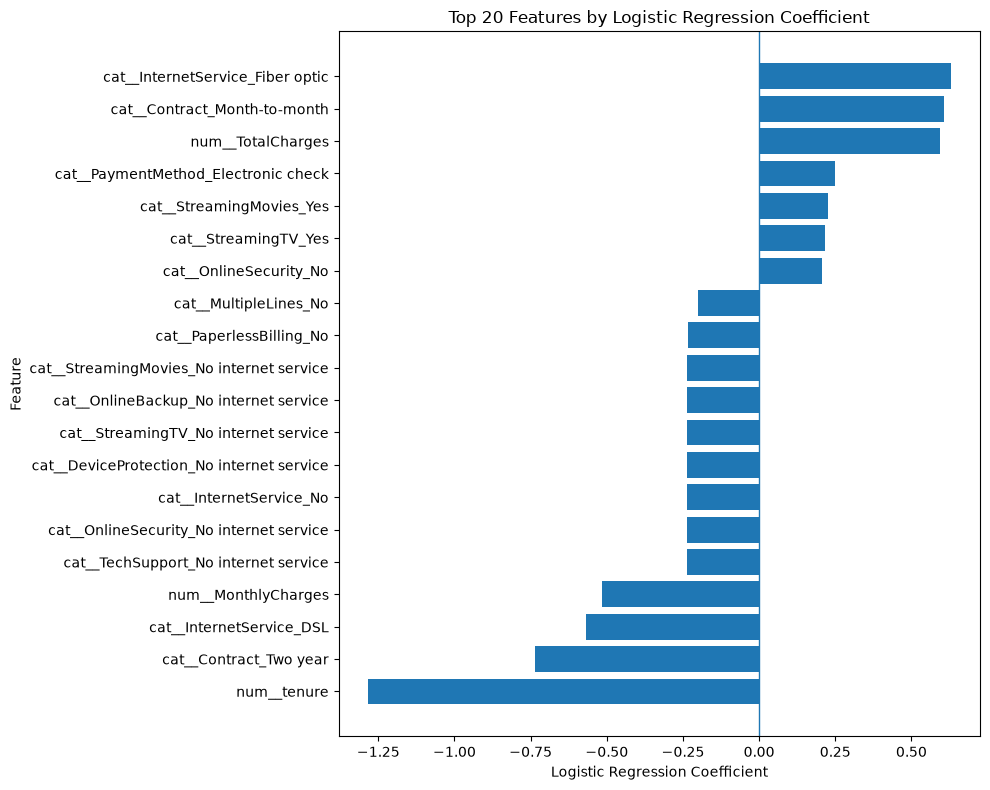

In [24]:
# 1. Create the coefficient visualization
import matplotlib.pyplot as plt

top_coefficients = (
    coef_df
    .sort_values("Abs_Coefficient", ascending=False)
    .head(20)
    .sort_values("Coefficient")
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_coefficients["Feature"],
    top_coefficients["Coefficient"]
)

plt.axvline(0, linewidth=1)

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top 20 Features by Logistic Regression Coefficient")

plt.tight_layout()
plt.show()

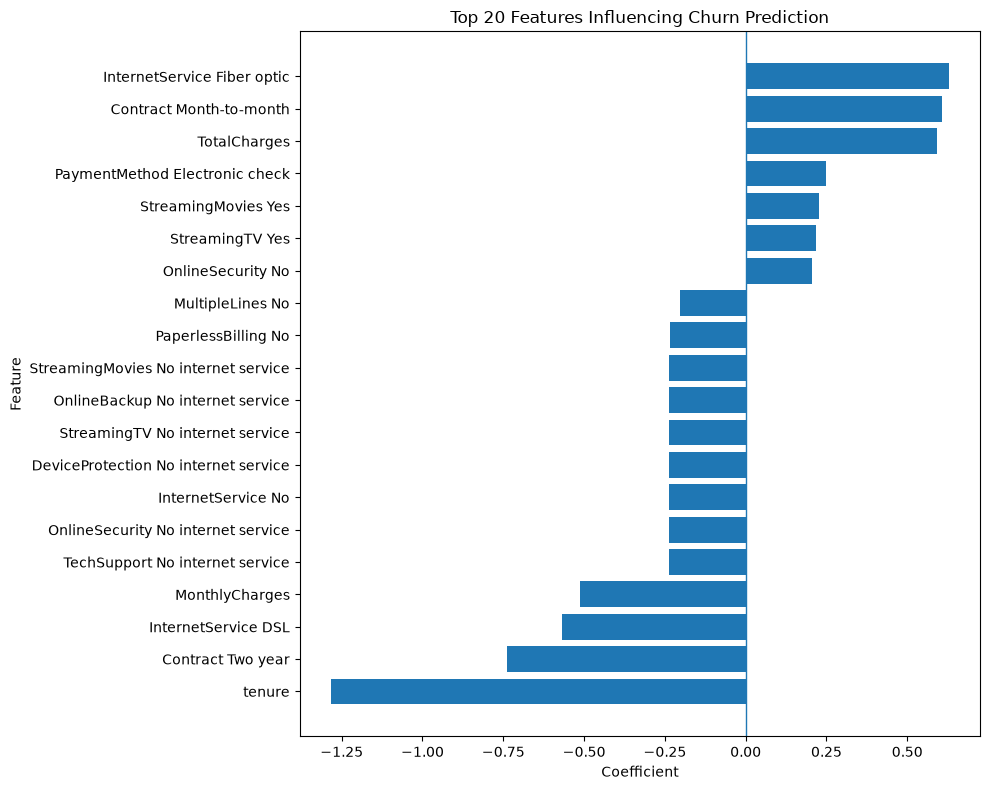

In [25]:
plot_df = top_coefficients.copy()

plot_df["Feature"] = (
    plot_df["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
    .str.replace("_", " ", regex=False)
)

plt.figure(figsize=(10, 8))

plt.barh(
    plot_df["Feature"],
    plot_df["Coefficient"]
)

plt.axvline(0, linewidth=1)

plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.title("Top 20 Features Influencing Churn Prediction")

plt.tight_layout()
plt.show()

### 11. Save the final model

In [27]:
# Step 1 — Save the final model and threshold
import joblib

final_model_package = {
    "model": final_model,
    "threshold": 0.40
}

joblib.dump(
    final_model_package,
    "../models/final_churn_model.joblib"
)

print("Final model saved successfully.")

Final model saved successfully.


In [28]:
# Step 2 — Verify that the saved model can be loaded
loaded_package = joblib.load(
    "../models/final_churn_model.joblib"
)

loaded_model = loaded_package["model"]
loaded_threshold = loaded_package["threshold"]

print("Threshold:", loaded_threshold)
print("Model:", loaded_model)

Threshold: 0.4
Model: Pipeline(steps=[('Preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
         

In [29]:
# Step 3 — Test a prediction
sample_customer = X_test.iloc[[0]]

sample_probability = loaded_model.predict_proba(sample_customer)[0, 1]

sample_prediction = int(
    sample_probability >= loaded_threshold
)

print("Churn probability:", round(sample_probability, 4))
print("Predicted churn:", sample_prediction)

Churn probability: 0.8776
Predicted churn: 1


In [30]:
# Step 4 — Add a reusable prediction function
def predict_churn(customer_data, model_package):
    model = model_package["model"]
    threshold = model_package["threshold"]

    probability = model.predict_proba(customer_data)[:, 1]

    prediction = (probability >= threshold).astype(int)

    return prediction, probability

In [31]:
prediction, probability = predict_churn(
    X_test.iloc[[0]],
    loaded_package
)

print("Prediction:", prediction[0])
print("Probability:", round(probability[0], 4))

Prediction: 1
Probability: 0.8776
